# Variação 2 — Gower + GNN (GraphSAGE)
> **Modo de dados:** por padrão (`SO_DROPOUT_GRADUATE = True`, na célula de dados) a análise usa só quem evadiu ou se formou (3.630 alunos); os 794 matriculados (Enrolled) ficam de lado e são estimados no fim (seção 6c). Com `False` volta às 3 classes do documento. Os números de referência do documento (4.424 alunos, 3 classes) não valem no modo padrão.
**Trabalho de Grafos · Cenário 3 (evasão e sucesso estudantil) · Modelagem – Frinhani**

**Pergunta:** saber quem são os vizinhos de um aluno (no Grafo 1, construído com a distância de Gower) ajuda a antecipar o desfecho dele, **além** das características do próprio aluno?

**Como responder:** comparamos, com os mesmos atributos e as mesmas dobras de validação cruzada:
1. **GraphSAGE** (modelo com grafo);
2. **MLP** (o mesmo modelo, sem arestas): a diferença GNN − MLP é o *ganho relacional*;
3. **GraphSAGE com arestas embaralhadas**: controle para saber se o ganho vem da estrutura;
4. **Regressão logística**: referência tradicional.

**Regras do documento:** (1) cada janela só usa o que se sabia naquele momento; (2) o desfecho **nunca** entra na distância nem nas arestas, só aparece como alvo de treino da GNN.
**Desenho indutivo (sem vazamento):** o grafo de treino é o kNN mútuo só entre alunos de treino; cada aluno de validação/teste recebe arestas **de entrada** vindas dos seus k vizinhos mais parecidos do treino (como um aluno novo). Alunos de teste nunca enviam mensagens.

Ambiente: `pip install torch torch-geometric scikit-learn pandas numpy matplotlib scipy igraph leidenalg` (Python 3.11+). Tempo esperado: ~10–15 min em CPU.

In [1]:
import os, io, zipfile, urllib.request, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import SAGEConv
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("figs", exist_ok=True); os.makedirs("resultados", exist_ok=True); os.makedirs("cache", exist_ok=True)

C:\Users\Wesley Batista\anaconda3\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Dados, janelas de tempo e preparação

In [2]:
# ---------- Dados ----------
url = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
CSV = "data.csv"
os.makedirs("data", exist_ok=True)
if not os.path.exists(CSV):
    try:
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())); z.extract("data.csv", "data")
    except Exception as e:
        raise SystemExit("Baixe o zip do UCI 697 manualmente e coloque data.csv em data/ (separador ';'). Erro: %s" % e)

raw = pd.read_csv(CSV, sep=";")
NOMES = ["marital","app_mode","app_order","course","shift","prev_qual","prev_grade","nationality",
         "mother_qual","father_qual","mother_occ","father_occ","admission_grade","displaced",
         "special_needs","debtor","tuition_ok","gender","scholarship","age","international",
         "s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval",
         "s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval",
         "unemployment","inflation","gdp","target"]
SO_DROPOUT_GRADUATE = True   # True: só Dropout x Graduate (decisão do grupo); os "Enrolled" ficam de lado e são estimados no final.
                             # False: as 3 classes (4.424 alunos), como no documento Frinhani.
assert raw.shape == (4424, 37), raw.shape          # 4.424 alunos, 36 variáveis + desfecho
df = raw.copy(); df.columns = NOMES
y_full = df.pop("target").map({"Dropout": 0, "Enrolled": 1, "Graduate": 2}).values.astype(int)
if SO_DROPOUT_GRADUATE:
    CLASSES = ["Dropout", "Graduate"]                # 0 = Evadiu, 1 = Formou
    df_enr = df[y_full == 1].reset_index(drop=True)  # matriculados (atrasados): fora da modelagem
    df = df[y_full != 1].reset_index(drop=True)
    y = np.where(y_full[y_full != 1] == 2, 1, 0)
else:
    CLASSES = ["Dropout", "Enrolled", "Graduate"]    # 0 = Evadiu, 1 = Atrasado, 2 = Formou
    df_enr, y = None, y_full
NCLS = len(CLASSES); GRAD = NCLS - 1; N = len(df); TAG = "bin" if SO_DROPOUT_GRADUATE else "3cl"
print(f"{N} alunos na modelagem" + (f" (+ {len(df_enr)} matriculados guardados para o final)" if df_enr is not None else ""))
print(pd.Series(y).map(dict(enumerate(CLASSES))).value_counts(normalize=True).round(3))

# ---------- Janelas de tempo (Regra 1) e desfecho fora do grafo (Regra 2) ----------
CAT_BASE = ["marital","app_mode","shift","prev_qual","nationality","mother_qual","father_qual",
            "mother_occ","father_occ","displaced","special_needs","gender","international"]   # 13
NUM_BASE = ["app_order","prev_grade","admission_grade","age"]                                   # 4
CAT_FIN  = CAT_BASE + ["debtor","tuition_ok","scholarship"]                                     # 16
NUM_S1   = ["s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval"]
NUM_S2   = ["s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval"]
JANELAS = {
    "1_matricula":   (CAT_BASE, NUM_BASE),
    "2_financeiro":  (CAT_FIN,  NUM_BASE),
    "3_fim_1sem":    (CAT_FIN,  NUM_BASE + NUM_S1),
    "4_fim_2sem":    (CAT_FIN,  NUM_BASE + NUM_S1 + NUM_S2),   # só referência
}
# curso, indicadores macroeconômicos ficam FORA da distância (decisão do documento)

# categorias com < 30 alunos (na base de modelagem) viram "outros" (-1); os matriculados seguem a mesma regra
for c_ in CAT_FIN:
    vc = df[c_].value_counts(); ok = vc[vc >= 30].index
    df[c_] = df[c_].where(df[c_].isin(ok), -1)
    if df_enr is not None: df_enr[c_] = df_enr[c_].where(df_enr[c_].isin(ok), -1)

ROT = {"marital":"Estado civil","app_mode":"Modo de ingresso","app_order":"Ordem de candidatura","shift":"Turno (1=diurno, 0=noturno)",
       "prev_qual":"Qualificação anterior","prev_grade":"Nota qualif. anterior","nationality":"Nacionalidade","mother_qual":"Escolaridade da mãe",
       "father_qual":"Escolaridade do pai","mother_occ":"Ocupação da mãe","father_occ":"Ocupação do pai","admission_grade":"Nota de admissão",
       "displaced":"Deslocado","special_needs":"Necessidades especiais","debtor":"Devedor","tuition_ok":"Mensalidade em dia","gender":"Gênero",
       "scholarship":"Bolsista","age":"Idade na matrícula","international":"Internacional",
       "s1_credited":"1º sem: unid. creditadas","s1_enrolled":"1º sem: unid. inscritas","s1_evaluations":"1º sem: avaliações",
       "s1_approved":"1º sem: aprovações","s1_grade":"1º sem: nota média","s1_without_eval":"1º sem: sem avaliação",
       "s2_credited":"2º sem: unid. creditadas","s2_enrolled":"2º sem: unid. inscritas","s2_evaluations":"2º sem: avaliações",
       "s2_approved":"2º sem: aprovações","s2_grade":"2º sem: nota média","s2_without_eval":"2º sem: sem avaliação"}
def rot(txt):
    for k in sorted(ROT, key=len, reverse=True): txt = txt.replace(k, ROT[k])
    return txt

3630 alunos na modelagem (+ 794 matriculados guardados para o final)
Graduate    0.609
Dropout     0.391
Name: proportion, dtype: float64


## 2. Distância de Gower (uma matriz por janela)
Todas as variáveis têm o mesmo peso; números entram como |a−b|/amplitude e categorias como 0 (iguais) ou 1 (diferentes). A amplitude usa só os atributos (nunca o desfecho).

In [3]:
def gower(cats, nums, d=None, ref=None, chunk=600):
    # d: tabela de alunos (padrão: df); ref: linhas usadas para a amplitude das numéricas (padrão: todos os de df)
    d = df if d is None else d; n = len(d); ref = np.arange(len(df)) if ref is None else np.asarray(ref)
    Cc = d[cats].values; X = d[nums].values.astype(np.float32)
    rang = X[ref].max(0) - X[ref].min(0); rang[rang == 0] = 1; X = X / rang
    p = len(cats) + len(nums); D = np.zeros((n, n), dtype=np.float32)
    for i in range(0, n, chunk):
        s = slice(i, i + chunk); acc = np.abs(X[s, None, :] - X[None, :, :]).sum(-1) + (Cc[s, None, :] != Cc[None, :, :]).sum(-1)
        D[s] = acc / p
    return D

DIST = {}
for nome, (cats, nums) in JANELAS.items():
    t = time.time(); DIST[nome] = gower(cats, nums); print(nome, DIST[nome].shape, f"{time.time()-t:.1f}s")

1_matricula (3630, 3630) 0.7s
2_financeiro (3630, 3630) 0.8s
3_fim_1sem (3630, 3630) 1.1s
4_fim_2sem (3630, 3630) 1.4s


## 3. Modelos e construção indutiva das arestas
* `knn_mutuo`: aresta i–j só se j está entre os k mais próximos de i **e** vice-versa (evita hubs falsos).
* `arestas_indutivas`: kNN mútuo dentro do treino (nos dois sentidos) + arestas treino → cada nó de validação/teste (um só sentido). Com `aleatorio=True` mantém o mesmo número de arestas, mas liga alunos sorteados (controle).
* Atributos dos nós: categorias em one-hot + números padronizados **com média/desvio do treino da dobra**.

In [4]:
def knn_mutuo(D, k):
    D = D.copy(); np.fill_diagonal(D, np.inf)
    nn_idx = np.argpartition(D, k, axis=1)[:, :k]
    A = np.zeros(D.shape, dtype=bool); A[np.repeat(np.arange(len(D)), k), nn_idx.ravel()] = True
    i, j = np.where(np.triu(A & A.T, 1))
    return i, j

def arestas_indutivas(D, tr, outros, k, aleatorio=False, rs=None):
    Dt = D[np.ix_(tr, tr)]
    if aleatorio:                                   # mesmo nº de arestas, vizinhos ao acaso
        ne = len(knn_mutuo(Dt, k)[0]); a = rs.integers(0, len(tr), ne); b = rs.integers(0, len(tr), ne)
        i, j = a[a != b], b[a != b]
        viz = rs.integers(0, len(tr), (len(outros), k))
    else:
        i, j = knn_mutuo(Dt, k)
        viz = np.argpartition(D[np.ix_(outros, tr)], k, axis=1)[:, :k]
    src = [tr[i], tr[j], tr[viz.ravel()]]
    dst = [tr[j], tr[i], np.repeat(outros, k)]
    return torch.tensor(np.vstack([np.concatenate(src), np.concatenate(dst)]), dtype=torch.long)

def monta_X(cats, nums, tr, d=None):
    d = df if d is None else d
    oh = pd.get_dummies(d[cats].astype(str), dtype=np.float32).values
    num = d[nums].values.astype(np.float32)
    mu, sd = num[tr].mean(0), num[tr].std(0); sd[sd == 0] = 1
    return torch.tensor(np.hstack([oh, (num - mu) / sd]), dtype=torch.float32)

class SAGE(nn.Module):
    def __init__(s, d, h=64, c=NCLS, p=0.5):
        super().__init__(); s.c1, s.c2, s.out, s.p = SAGEConv(d, h), SAGEConv(h, h), nn.Linear(h, c), p
    def forward(s, x, ei, emb=False):
        x = F.dropout(x, s.p, s.training); x = F.relu(s.c1(x, ei))
        x = F.dropout(x, s.p, s.training); h = F.relu(s.c2(x, ei))
        return h if emb else s.out(F.dropout(h, s.p, s.training))

class MLP(nn.Module):                               # mesmo modelo, sem arestas
    def __init__(s, d, h=64, c=NCLS, p=0.5):
        super().__init__(); s.l1, s.l2, s.out, s.p = nn.Linear(d, h), nn.Linear(h, h), nn.Linear(h, c), p
    def forward(s, x, ei=None, emb=False):
        x = F.dropout(x, s.p, s.training); x = F.relu(s.l1(x))
        x = F.dropout(x, s.p, s.training); h = F.relu(s.l2(x))
        return h if emb else s.out(F.dropout(h, s.p, s.training))

ytt = torch.tensor(y, dtype=torch.long)

def treina(model, X, ei, tr, va, epocas=400, paciencia=40, lr=0.01, hist=None):
    w = torch.tensor(len(tr) / (NCLS * np.bincount(y[tr], minlength=NCLS)), dtype=torch.float32)  # peso inverso à frequência
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    melhor, estado, sem = -1, None, 0
    for ep in range(epocas):
        model.train(); opt.zero_grad()
        loss = F.cross_entropy(model(X, ei)[tr], ytt[tr], weight=w); loss.backward(); opt.step()   # desfecho só entra na perda do treino
        model.eval()
        with torch.no_grad():
            o = model(X, ei)[va]; pv = o.argmax(1).numpy(); f = f1_score(y[va], pv, average="macro")
            if hist is not None: hist.append((loss.item(), F.cross_entropy(o, ytt[va], weight=w).item(), float((pv == y[va]).mean())))
        if f > melhor: melhor, estado, sem = f, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            sem += 1
            if sem >= paciencia: break
    model.load_state_dict(estado); model.eval()
    with torch.no_grad(): return F.softmax(model(X, ei), 1).numpy()

## 4. Validação cruzada estratificada (5 dobras) nas 4 janelas
`K_GNN` usa os k escolhidos pela estabilidade no Método 1 do documento (40, 50, 40, 40). Se o grupo mudar o k, altere aqui.

In [5]:
K_GNN = {"1_matricula": 40, "2_financeiro": 50, "3_fim_1sem": 40, "4_fim_2sem": 40}

def avalia(P, yte):
    pred = P.argmax(1)
    return dict(f1=f1_score(yte, pred, average="macro"), bacc=balanced_accuracy_score(yte, pred),
                auc_evasao=roc_auc_score(yte == 0, P[:, 0]))

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
linhas, OOF, HIST = [], {}, {}
for nome, (cats, nums) in JANELAS.items():
    D, k = DIST[nome], K_GNN[nome]; oof = np.zeros((N, NCLS)); t = time.time(); H = []
    for f, (trv, te) in enumerate(skf.split(np.zeros(N), y)):
        tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=f)
        outros = np.concatenate([va, te])
        X = monta_X(cats, nums, tr)
        ei   = arestas_indutivas(D, tr, outros, k, rs=np.random.default_rng(f))
        ei_r = arestas_indutivas(D, tr, outros, k, aleatorio=True, rs=np.random.default_rng(f))
        torch.manual_seed(f); P_g = treina(SAGE(X.shape[1]), X, ei,   tr, va, hist=H if f == 0 else None)[te]
        torch.manual_seed(f); P_r = treina(SAGE(X.shape[1]), X, ei_r, tr, va)[te]
        torch.manual_seed(f); P_m = treina(MLP(X.shape[1]),  X, None, tr, va)[te]
        lr_ = LogisticRegression(class_weight="balanced", C=1, max_iter=2000).fit(X[tr].numpy(), y[tr])
        P_l = lr_.predict_proba(X[te].numpy())
        oof[te] = P_g
        for mod, P in [("GraphSAGE", P_g), ("MLP", P_m), ("GraphSAGE embaralhada", P_r), ("Logística", P_l)]:
            linhas.append(dict(janela=nome, dobra=f, modelo=mod, **avalia(P, y[te])))
    OOF[nome] = oof; HIST[nome] = H; print(nome, f"{time.time()-t:.0f}s")
res = pd.DataFrame(linhas); res.to_csv("resultados/var2_gower_gnn_por_dobra.csv", index=False)

1_matricula 67s
2_financeiro 69s
3_fim_1sem 79s
4_fim_2sem 78s


## 5. Resultados: a vizinhança ajuda a prever?

f1          bacc        auc_evasao  \
                                     mean    std   mean    std       mean   
janela       modelo                                                         
1_matricula  GraphSAGE              0.682  0.016  0.679  0.015      0.726   
             GraphSAGE embaralhada  0.681  0.011  0.681  0.011      0.736   
             Logística              0.672  0.018  0.675  0.018      0.730   
             MLP                    0.679  0.019  0.681  0.019      0.738   
2_financeiro GraphSAGE              0.744  0.010  0.740  0.007      0.820   
             GraphSAGE embaralhada  0.741  0.010  0.740  0.011      0.826   
             Logística              0.744  0.013  0.745  0.013      0.826   
             MLP                    0.748  0.016  0.747  0.017      0.828   
3_fim_1sem   GraphSAGE              0.851  0.011  0.845  0.009      0.916   
             GraphSAGE embaralhada  0.861  0.009  0.857  0.006      0.919   
             Logística              0.868  0.011  0.867  0.010      0.928   
             MLP                    0.856  0.005  0.851  0.004      0.923   
4_fim_2sem   GraphSAGE              0.888  0.004  0.880  0.003      0.942   
             GraphSAGE embaralhada  0.886  0.005  0.881  0.004      0.944   
             Logística              0.895  0.010  0.894  0.009      0.948   
             MLP                    0.886  0.012  0.882  0.012      0.939   

                                           
                                      std  
janela       modelo                        
1_matricula  GraphSAGE              0.016  
             GraphSAGE embaralhada  0.013  
             Logística              0.014  
             MLP                    0.014  
2_financeiro GraphSAGE              0.005  
             GraphSAGE embaralhada  0.012  
             Logística              0.010  
             MLP                    0.012  
3_fim_1sem   GraphSAGE              0.005  
             GraphSAGE embaralhada  0.009  
             Logística              0.008  
             MLP                    0.007  
4_fim_2sem   GraphSAGE              0.009  
             GraphSAGE embaralhada  0.006  
             Logística              0.006  
             MLP                    0.010

,Ganho GNN−MLP (F1),desvio entre dobras,dobras em que a GNN venceu,GNN − GNN embaralhada,AUC evasão GNN / MLP / Logística
janela,,,,,
1_matricula,0.003,0.006,3,0.000,0.726 / 0.738 / 0.730
2_financeiro,-0.004,0.009,2,0.003,0.820 / 0.828 / 0.826
3_fim_1sem,-0.005,0.010,2,-0.010,0.916 / 0.923 / 0.928
4_fim_2sem,0.002,0.011,3,0.002,0.942 / 0.939 / 0.948


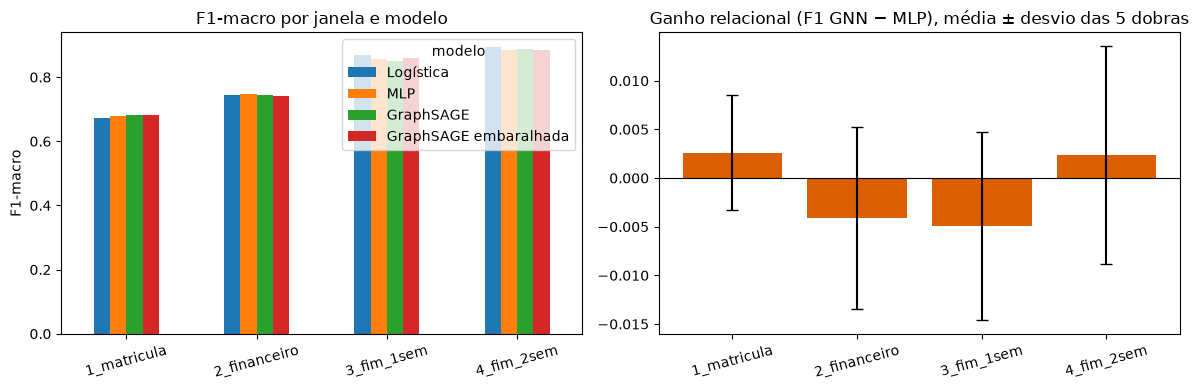

In [6]:
resumo = res.groupby(["janela", "modelo"])[["f1", "bacc", "auc_evasao"]].agg(["mean", "std"]).round(3)
display(resumo)

w = res.pivot_table(index=["janela", "dobra"], columns="modelo", values="f1")
ganho = pd.DataFrame({
    "Ganho GNN−MLP (F1)":        (w["GraphSAGE"] - w["MLP"]).groupby("janela").mean(),
    "desvio entre dobras":       (w["GraphSAGE"] - w["MLP"]).groupby("janela").std(),
    "dobras em que a GNN venceu": (w["GraphSAGE"] > w["MLP"]).groupby("janela").sum(),
    "GNN − GNN embaralhada":     (w["GraphSAGE"] - w["GraphSAGE embaralhada"]).groupby("janela").mean(),
}).round(3)
auc = res.pivot_table(index="janela", columns="modelo", values="auc_evasao").round(3)[["GraphSAGE", "MLP", "Logística"]]
ganho["AUC evasão GNN / MLP / Logística"] = auc.apply(lambda r: " / ".join(f"{v:.3f}" for v in r), axis=1)
display(ganho); ganho.to_csv("resultados/var2_ganho_relacional.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m = res.groupby(["janela", "modelo"])["f1"].mean().unstack()[["Logística", "MLP", "GraphSAGE", "GraphSAGE embaralhada"]]
m.plot.bar(ax=ax[0], rot=15); ax[0].set_title("F1-macro por janela e modelo"); ax[0].set_ylabel("F1-macro"); ax[0].set_xlabel("")
d = (w["GraphSAGE"] - w["MLP"]).groupby("janela")
ax[1].bar(d.mean().index, d.mean(), yerr=d.std(), capsize=4, color="#d95f02"); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Ganho relacional (F1 GNN − MLP), média ± desvio das 5 dobras"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("figs/var2_desempenho.png", dpi=150); plt.show()

## 6. Casos ambíguos: onde a GNN fica em dúvida
Para cada aluno que evadiu ou se formou, vemos se o vizinho **mais parecido** (menor distância de Gower) teve o final oposto. Depois comparamos entropia (0 = certeza, 1 = dúvida total) e acerto da GNN, com as previsões fora da dobra.

,janela,pct_vizinho_oposto,entropia_oposto,entropia_demais,acerto_oposto,acerto_demais
0,1_matricula,40.1,0.910,0.878,49.2,84.1
1,2_financeiro,33.0,0.884,0.755,51.8,88.0
2,3_fim_1sem,26.1,0.733,0.541,65.0,93.5
3,4_fim_2sem,20.5,0.633,0.424,66.4,95.6


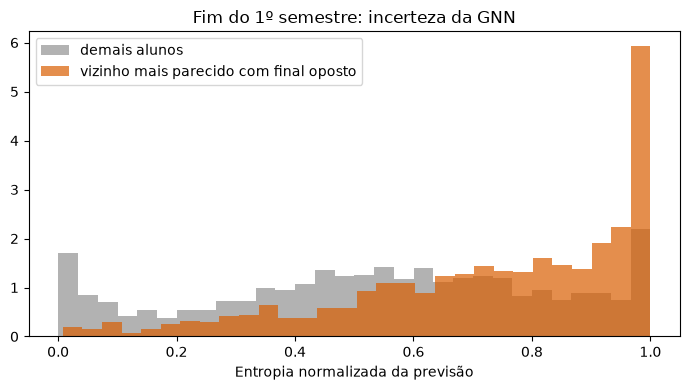

Acerto por classe (fim do 1º sem): {'Dropout': 0.777, 'Graduate': 0.914}


In [7]:
def ambiguos(nome):
    D = DIST[nome].copy(); np.fill_diagonal(D, np.inf); nn = D.argmin(1)
    elegivel = np.isin(y, [0, GRAD])
    oposto = elegivel & np.isin(y[nn], [0, GRAD]) & (y != y[nn])
    P = OOF[nome]; ent = -(P * np.log(P + 1e-12)).sum(1) / np.log(NCLS); ok = P.argmax(1) == y
    return dict(janela=nome, pct_vizinho_oposto=round(100 * oposto[elegivel].mean(), 1),
                entropia_oposto=round(ent[oposto].mean(), 3), entropia_demais=round(ent[~oposto].mean(), 3),
                acerto_oposto=round(100 * ok[oposto].mean(), 1), acerto_demais=round(100 * ok[~oposto].mean(), 1)), oposto, ent

amb = pd.DataFrame([ambiguos(n)[0] for n in JANELAS]); display(amb); amb.to_csv("resultados/var2_ambiguos.csv", index=False)

_, oposto, ent = ambiguos("3_fim_1sem")
plt.figure(figsize=(7, 4))
plt.hist(ent[~oposto], bins=30, alpha=.6, color="gray", density=True, label="demais alunos")
plt.hist(ent[oposto], bins=30, alpha=.7, color="#d95f02", density=True, label="vizinho mais parecido com final oposto")
plt.xlabel("Entropia normalizada da previsão"); plt.title("Fim do 1º semestre: incerteza da GNN"); plt.legend()
plt.tight_layout(); plt.savefig("figs/var2_entropia.png", dpi=150); plt.show()

P = OOF["3_fim_1sem"]; pred = P.argmax(1)
print("Acerto por classe (fim do 1º sem):", {CLASSES[c]: round(float((pred[y == c] == c).mean()), 3) for c in range(NCLS)})

## 6b. Gráficos para a apresentação: curvas de treino e matriz de confusão
* Curvas (loss e acurácia de validação por época): dobra 0 da janela escolhida.
* Matriz de confusão: previsões **fora da dobra** de todos os alunos (cada aluno é previsto por um modelo que não o viu no treino), com acurácia, F1-macro e AUC de evasão.

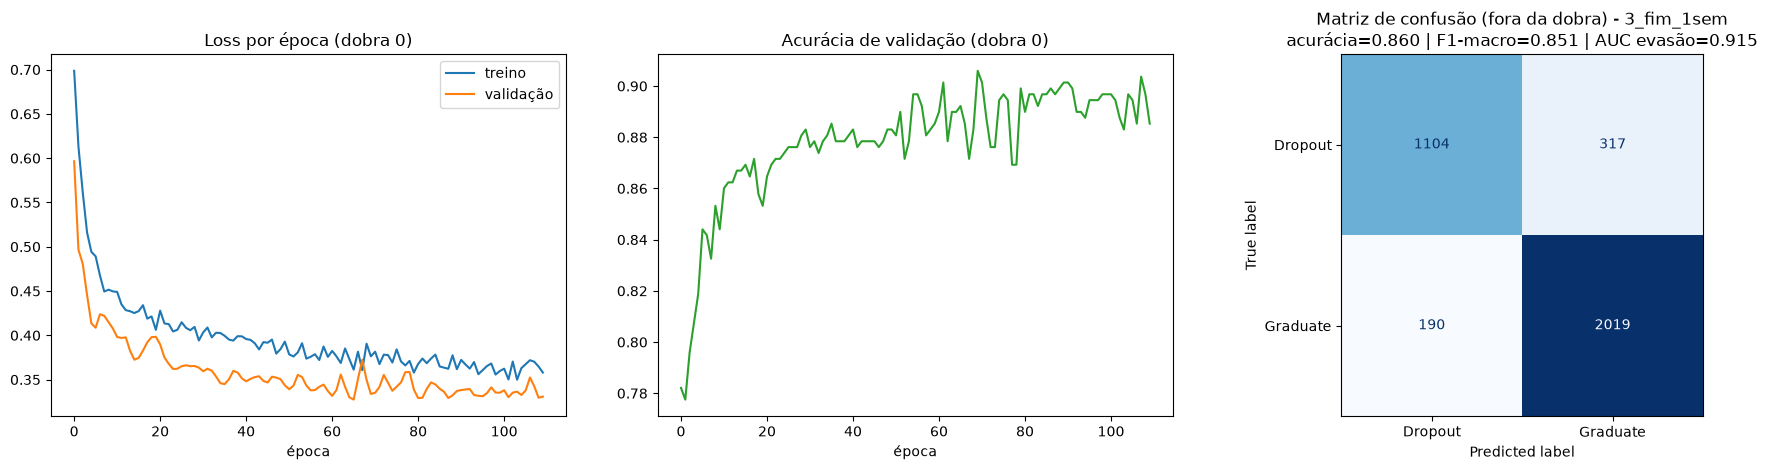

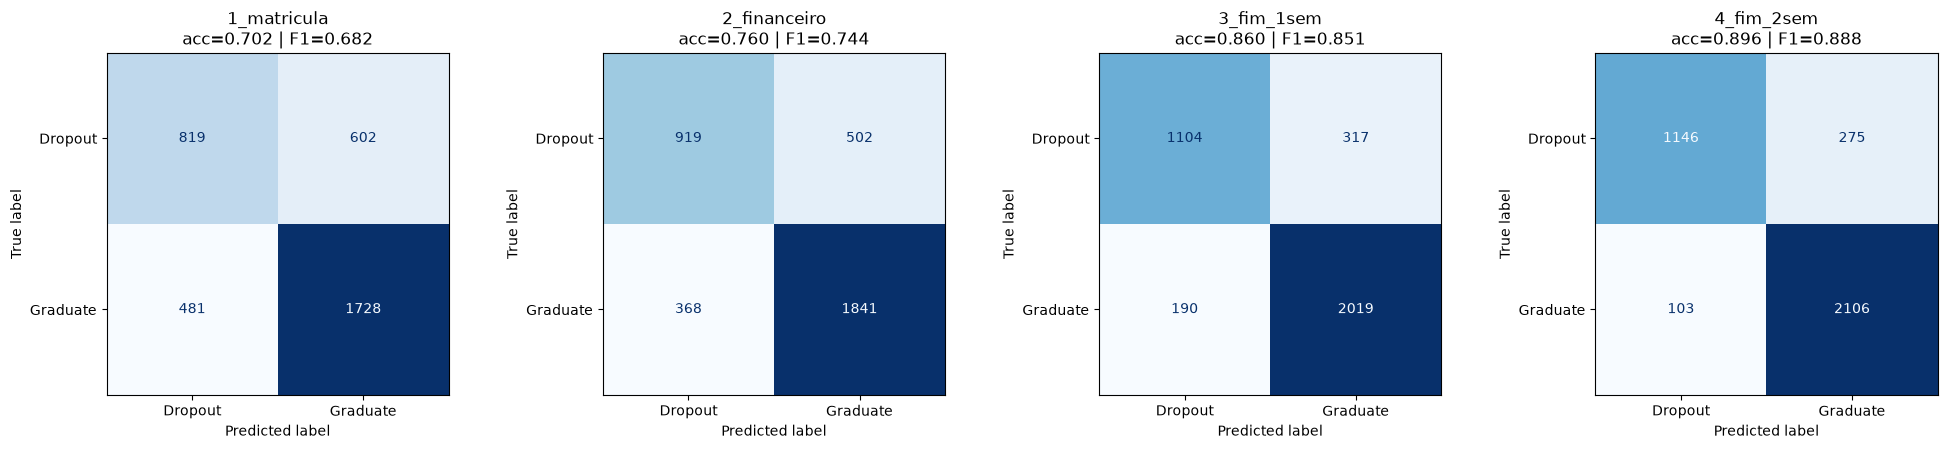

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
JF = "3_fim_1sem"                                   # janela exibida; troque para outra se quiser
h = np.array(HIST[JF]); P = OOF[JF]; pred = P.argmax(1)
acc = (pred == y).mean(); f1m = f1_score(y, pred, average="macro"); auc_e = roc_auc_score(y == 0, P[:, 0])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(h[:, 0], label="treino"); ax[0].plot(h[:, 1], label="validação"); ax[0].set_title("Loss por época (dobra 0)"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(h[:, 2], color="tab:green"); ax[1].set_title("Acurácia de validação (dobra 0)"); ax[1].set_xlabel("época")
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=CLASSES, cmap="Blues", ax=ax[2], colorbar=False)
ax[2].set_title(f"Matriz de confusão (fora da dobra) - {JF}\nacurácia={acc:.3f} | F1-macro={f1m:.3f} | AUC evasão={auc_e:.3f}")
plt.tight_layout(); plt.savefig(f"figs/var2_curvas_confusao_{JF}.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, nome in zip(ax, JANELAS):
    pr = OOF[nome].argmax(1); ConfusionMatrixDisplay.from_predictions(y, pr, display_labels=CLASSES, cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"{nome}\nacc={(pr == y).mean():.3f} | F1={f1_score(y, pr, average='macro'):.3f}")
plt.tight_layout(); plt.savefig("figs/var2_confusao_janelas.png", dpi=150); plt.show()

for nome in JANELAS:                                 # previsões por aluno (mesmo formato do material do grupo)
    pd.DataFrame({"aluno": np.arange(N), "situacao": [CLASSES[v] for v in y], "previsto_gnn": [CLASSES[v] for v in OOF[nome].argmax(1)],
                  **{f"p_{c}": OOF[nome][:, i] for i, c in enumerate(CLASSES)}}).to_csv(f"resultados/var2_previsoes_{nome}.csv", index=False)

## 6d. O grafo (Gower) colorido pela situação real e pela GNN
O Grafo 1 desta variação: cada ponto é um aluno, ligado aos mais parecidos pela distância de Gower (kNN mútuo). Painéis: (1) situação real, com **linhas pretas** ligando alunos parecidos com final oposto; (2) previsão da GNN fora da dobra, com os **erros** circulados; (3) risco previsto de evasão, P(Dropout); (4) grupos obtidos rodando o Leiden **uma vez** sobre este mesmo grafo, só para dar nome às regiões do desenho - a análise de comunidades de verdade é a variação do Leiden (1 ou 3), não esta. As posições vêm de um layout de força do `igraph` (`pip install igraph`).

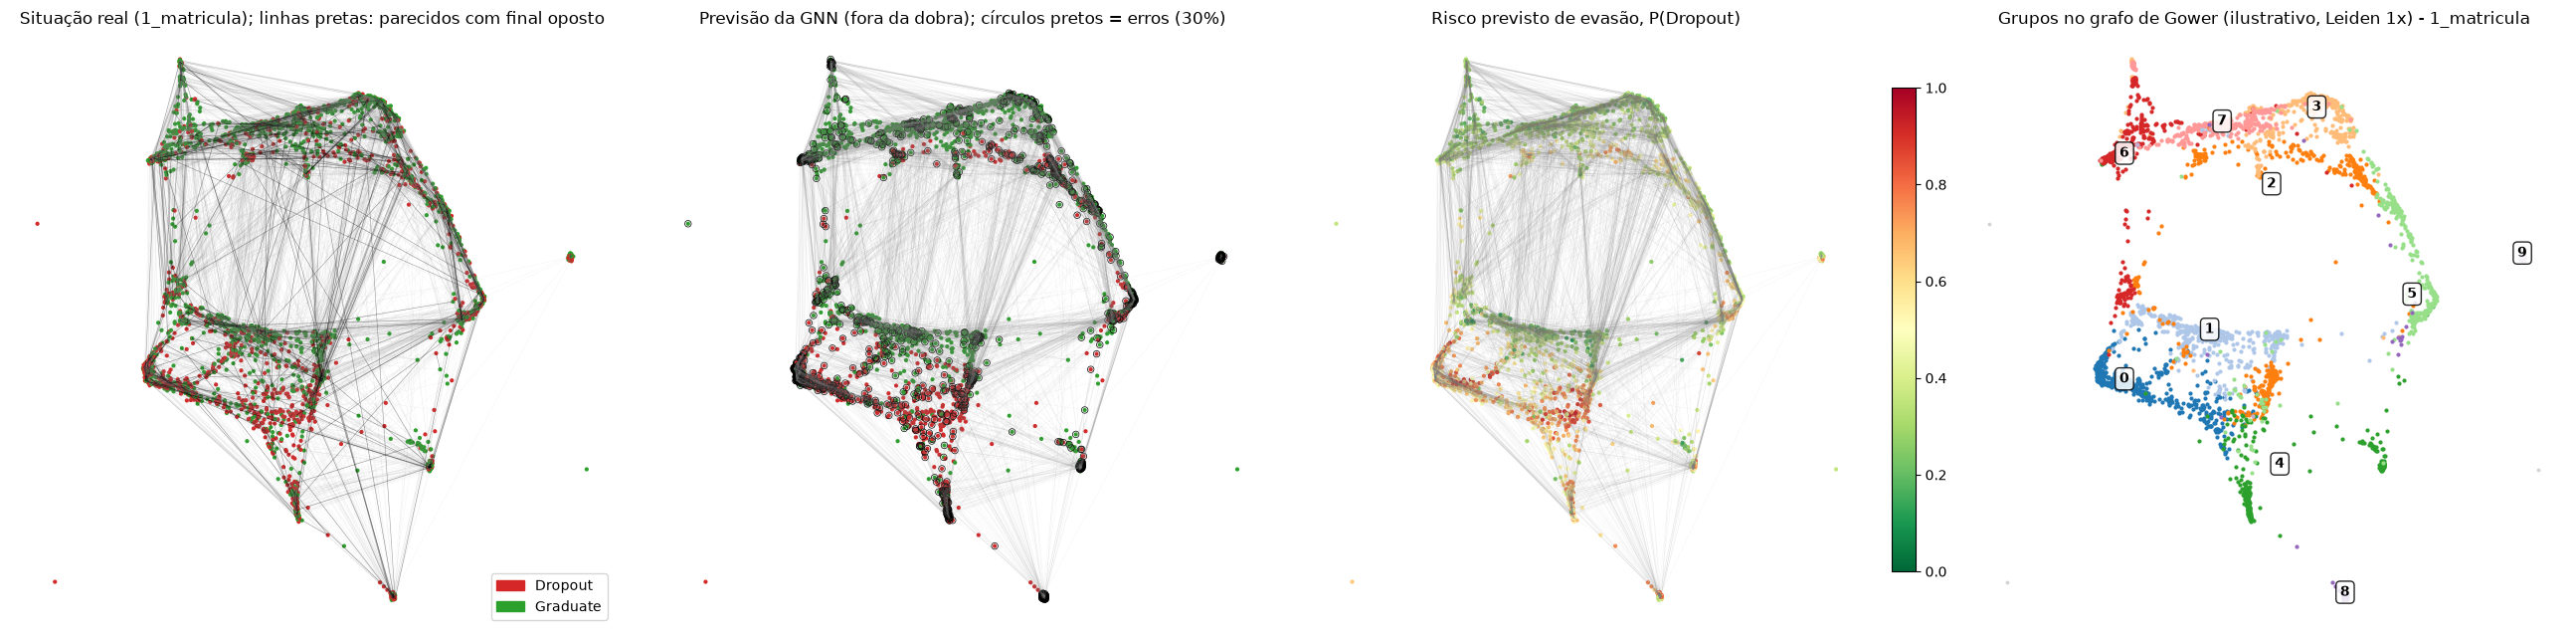

Legenda dos grupos (1_matricula), ilustrativa (Leiden rodado 1x sobre o grafo de Gower, não é a variação 1/3):


,comunidade,alunos,evasao,o que caracteriza (traço mais marcante)
0,8,148,69%,Escolaridade do pai=34 (68%)
1,0,528,59%,Modo de ingresso=39 (78%)
2,2,467,52%,Gênero=1 (98%)
3,4,377,49%,Deslocado=0 (60%)
4,5,366,39%,Escolaridade da mãe=3 (67%)
5,9,86,38%,Internacional=1 (99%)
6,1,527,26%,Deslocado=0 (98%)
7,6,362,26%,Ocupação da mãe=9 (94%)
8,7,354,23%,Deslocado=1 (100%)
9,3,412,21%,Escolaridade da mãe=1 (64%)


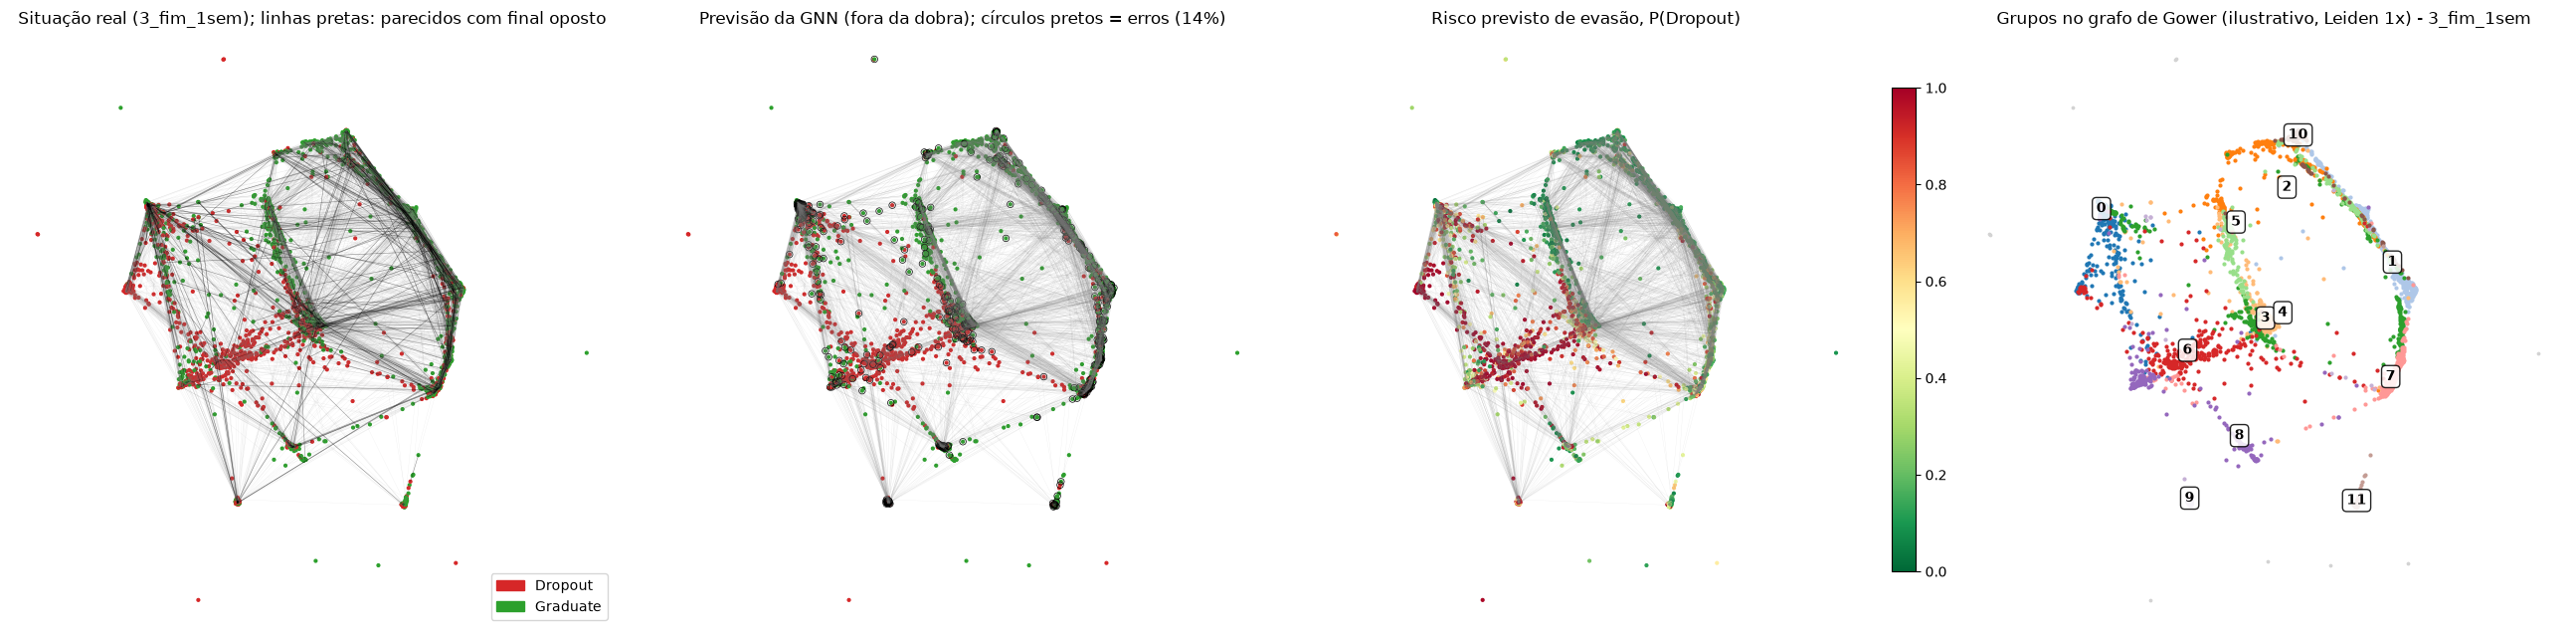

Legenda dos grupos (3_fim_1sem), ilustrativa (Leiden rodado 1x sobre o grafo de Gower, não é a variação 1/3):


,comunidade,alunos,evasao,o que caracteriza (traço mais marcante)
0,6,311,92%,Mensalidade em dia=0 (85%)
1,9,131,69%,Escolaridade do pai=34 (76%)
2,0,517,55%,Modo de ingresso=39 (72%)
3,4,315,53%,Gênero=1 (77%)
4,8,309,45%,Deslocado=0 (60%)
5,7,310,35%,Ocupação da mãe=2 (55%)
6,11,79,35%,Internacional=1 (100%)
7,3,372,33%,Escolaridade da mãe=1 (52%)
8,1,435,17%,Escolaridade da mãe=1 (61%)
9,10,121,16%,Escolaridade da mãe=19 (95%)


In [9]:
import igraph as ig, leidenalg as la, random
from matplotlib.collections import LineCollection
from matplotlib.patches import Patch
COR = np.array(["#d62728", "#2ca02c"]) if NCLS == 2 else np.array(["#d62728", "#f1c40f", "#2ca02c"])

def rotulo_curto_gower(memb, jan, c, minimo=30):
    # frase curta com a característica mais marcante da comunidade c (maior |z| numérico, ou maior lift categórico)
    cats, nums = JANELAS[jan]; m = memb == c
    if m.sum() < minimo: return ""
    z = (df[nums] - df[nums].mean()) / df[nums].std(); zc = z[m].mean()
    melhor_num = zc.abs().idxmax(); cand = [(abs(zc[melhor_num]), f"{rot(melhor_num)} {zc[melhor_num]:+.1f}dp")]
    for v in cats:
        s_ = df.loc[m, v].value_counts(normalize=True); base_v = df[v].value_counts(normalize=True)
        for val, sh in s_.items():
            if sh >= 0.5:
                lift = sh / base_v[val]
                if lift >= 1.3: cand.append((lift, f"{rot(v)}={val} ({sh:.0%})"))
    cand.sort(key=lambda t: -t[0]); return cand[0][1] if cand else ""

def figura_grafo(jan, minimo=30):
    D, k = DIST[jan], K_GNN[jan]; i, j = knn_mutuo(D, k); arq = f"cache/pos_gower_{TAG}_{jan}.npy"
    if os.path.exists(arq): emb = np.load(arq)
    else:
        g = ig.Graph(n=N, edges=list(zip(i.tolist(), j.tolist()))); g.es["weight"] = (1 - D[i, j]).tolist()
        random.seed(SEED); emb = np.array(g.layout_drl(weights="weight").coords); np.save(arq, emb)
    g = ig.Graph(n=N, edges=list(zip(i.tolist(), j.tolist()))); g.es["weight"] = (1 - D[i, j]).tolist()
    memb = np.array(la.find_partition(g, la.ModularityVertexPartition, weights="weight", seed=0, n_iterations=-1).membership)
    tam = np.bincount(memb); grandes = [c for c in np.argsort(-tam) if tam[c] >= minimo][:12]; cmap = plt.get_cmap("tab20")
    rotulos = {c: rotulo_curto_gower(memb, jan, c, minimo) for c in grandes}
    P = OOF[jan]; pred = P.argmax(1); erro = pred != y
    sel = np.random.default_rng(SEED).choice(len(i), min(15000, len(i)), replace=False); seg = np.stack([emb[i[sel]], emb[j[sel]]], 1)
    disc = np.where(np.isin(y[i], [0, GRAD]) & np.isin(y[j], [0, GRAD]) & (y[i] != y[j]))[0]
    disc = np.random.default_rng(SEED).choice(disc, min(800, len(disc)), replace=False)
    fig, ax = plt.subplots(1, 4, figsize=(26, 6.5))
    for a in ax[:3]: a.add_collection(LineCollection(seg, colors="gray", linewidths=.2, alpha=.15)); a.set_axis_off()
    ax[3].scatter(*emb[~np.isin(memb, grandes)].T, s=3, color="lightgray")
    for kk, c in enumerate(grandes):
        m = memb == c; ax[3].scatter(*emb[m].T, s=4, color=cmap(kk % 20)); cx, cy = np.median(emb[m], 0)
        ax[3].text(cx, cy, str(c), fontsize=10, weight="bold", ha="center", bbox=dict(boxstyle="round", fc="white", alpha=.85))
    ax[3].set_title(f"Grupos no grafo de Gower (ilustrativo, Leiden 1x) - {jan}"); ax[3].set_axis_off(); ax[3].autoscale()
    ax[0].scatter(*emb.T, c=COR[y], s=4); ax[0].add_collection(LineCollection(np.stack([emb[i[disc]], emb[j[disc]]], 1), colors="black", linewidths=.4, alpha=.4, zorder=3))
    ax[0].set_title(f"Situação real ({jan}); linhas pretas: parecidos com final oposto")
    ax[0].legend(handles=[Patch(color=COR[c], label=CLASSES[c]) for c in range(NCLS)], loc="lower right")
    ax[1].scatter(*emb.T, c=COR[pred], s=4); ax[1].scatter(*emb[erro].T, s=22, facecolors="none", edgecolors="black", linewidths=.5)
    ax[1].set_title(f"Previsão da GNN (fora da dobra); círculos pretos = erros ({erro.mean():.0%})")
    sc = ax[2].scatter(*emb.T, c=P[:, 0], s=4, cmap="RdYlGn_r", vmin=0, vmax=1); plt.colorbar(sc, ax=ax[2], fraction=.04); ax[2].set_title("Risco previsto de evasão, P(Dropout)")
    for a in ax: a.autoscale()
    plt.tight_layout(); plt.savefig(f"figs/var2_grafo_gower_{jan}.png", dpi=150); plt.show()
    ordem = sorted(grandes, key=lambda c: -(y[memb == c] == 0).mean())
    leg = pd.DataFrame({"comunidade": ordem, "alunos": [tam[o] for o in ordem], "evasao": [f"{(y[memb == o] == 0).mean():.0%}" for o in ordem],
                        "o que caracteriza (traço mais marcante)": [rotulos[o] for o in ordem]})
    print(f"Legenda dos grupos ({jan}), ilustrativa (Leiden rodado 1x sobre o grafo de Gower, não é a variação 1/3):"); display(leg)

for jan in ["1_matricula", "3_fim_1sem"]: figura_grafo(jan)

### Perfis mais associados a Dropout e a Graduate previstos pela GNN
Mesma lógica do *lift* (P(previsão | regra) / P(previsão)): quais características, isoladas ou em pares, mais aparecem entre os alunos que a **GNN prevê** como Dropout e como Graduate (previsões fora da dobra). Só entram regras com ≥ 3% dos alunos e p-valor corrigido (Benjamini-Hochberg) < 0,01. É associação com a previsão do modelo, não causa.

In [10]:
from scipy.stats import binom

def itens(cats, nums, nbins=4, min_sup=0.03):
    """Transforma cada categoria (var=valor) e cada faixa de quartil de uma variável numérica em um 'item' verdadeiro/falso."""
    cols, nomes = [], []
    for v in cats:
        for val, n in df[v].value_counts().items():
            if n >= min_sup * N: cols.append((df[v] == val).values); nomes.append(f"{v}={val}")
    for v in nums:
        b = pd.qcut(df[v], nbins, duplicates="drop")
        for iv in b.cat.categories:
            m = (b == iv).values
            if m.sum() >= min_sup * N: cols.append(m); nomes.append(f"{v} em [{iv.left:.1f}; {iv.right:.1f}]")
    return np.array(cols).T, np.array(nomes)

def bh(p):                                           # correção de Benjamini-Hochberg
    p = np.asarray(p); o = np.argsort(p); q = np.empty_like(p); m = len(p)
    q[o] = np.minimum.accumulate((p[o] * m / (np.arange(m) + 1))[::-1])[::-1]; return np.minimum(q, 1)

def regras_lift(alvo, cats, nums, classe, min_sup=0.03, ganho_min=0.05, topo=8):
    """Itens isolados e pares de itens mais associados a `classe` (lift = P(classe | regra) / P(classe)).
    Pares só entram se somam pelo menos `ganho_min` de lift sobre o melhor item isolado (combinação, não fator solto)."""
    A, nomes = itens(cats, nums, min_sup=min_sup); A = A.astype(np.float32)
    t = (np.asarray(alvo) == classe).astype(np.float32); base = t.mean()
    S, T = A.sum(0), A.T @ t; lift1 = (T / S) / base
    n2 = A.T @ A; t2 = A.T @ (A * t[:, None])
    ii, jj = np.where(np.triu(n2 >= min_sup * N, 1))
    rows = [(nomes[i], S[i], T[i], lift1[i], 0.0) for i in range(len(nomes))]
    for i, j in zip(ii, jj):
        l = (t2[i, j] / n2[i, j]) / base; g = l - max(lift1[i], lift1[j])
        if g >= ganho_min: rows.append((nomes[i] + " E " + nomes[j], n2[i, j], t2[i, j], l, g))
    r = pd.DataFrame(rows, columns=["regra", "n", "n_classe", "lift", "ganho_sobre_item"])
    r["confianca"] = r["n_classe"] / r["n"]; r["suporte"] = r["n"] / N
    r["q_BH"] = bh(binom.sf(r["n_classe"].values - 1, r["n"].values.astype(int), base))
    r = r[(r["q_BH"] < 0.01) & (r["lift"] > 1)].sort_values("lift", ascending=False)
    return r.head(topo).reset_index(drop=True), base

def plota_regras(ax, r, titulo, cor, base):
    if len(r) == 0:
        ax.text(.5, .5, "nenhuma regra passou nos filtros", ha="center"); ax.set_title(titulo, fontsize=10); return
    ax.barh(range(len(r))[::-1], r["lift"], color=cor); ax.set_yticks(range(len(r))[::-1])
    ax.set_yticklabels([rot(x)[:95] for x in r["regra"]], fontsize=8); ax.axvline(1, ls="--", color="k", lw=.8)
    for y_, (l, c, n) in zip(range(len(r))[::-1], zip(r["lift"], r["confianca"], r["n"])):
        ax.text(l, y_, f"  lift {l:.2f} | {c:.0%} | n={int(n)}", va="center", fontsize=8)
    ax.set_xlim(0, max(r["lift"].max() * 1.45, 1.5)); ax.set_title(f"{titulo}  (taxa geral {base:.0%})", fontsize=10)

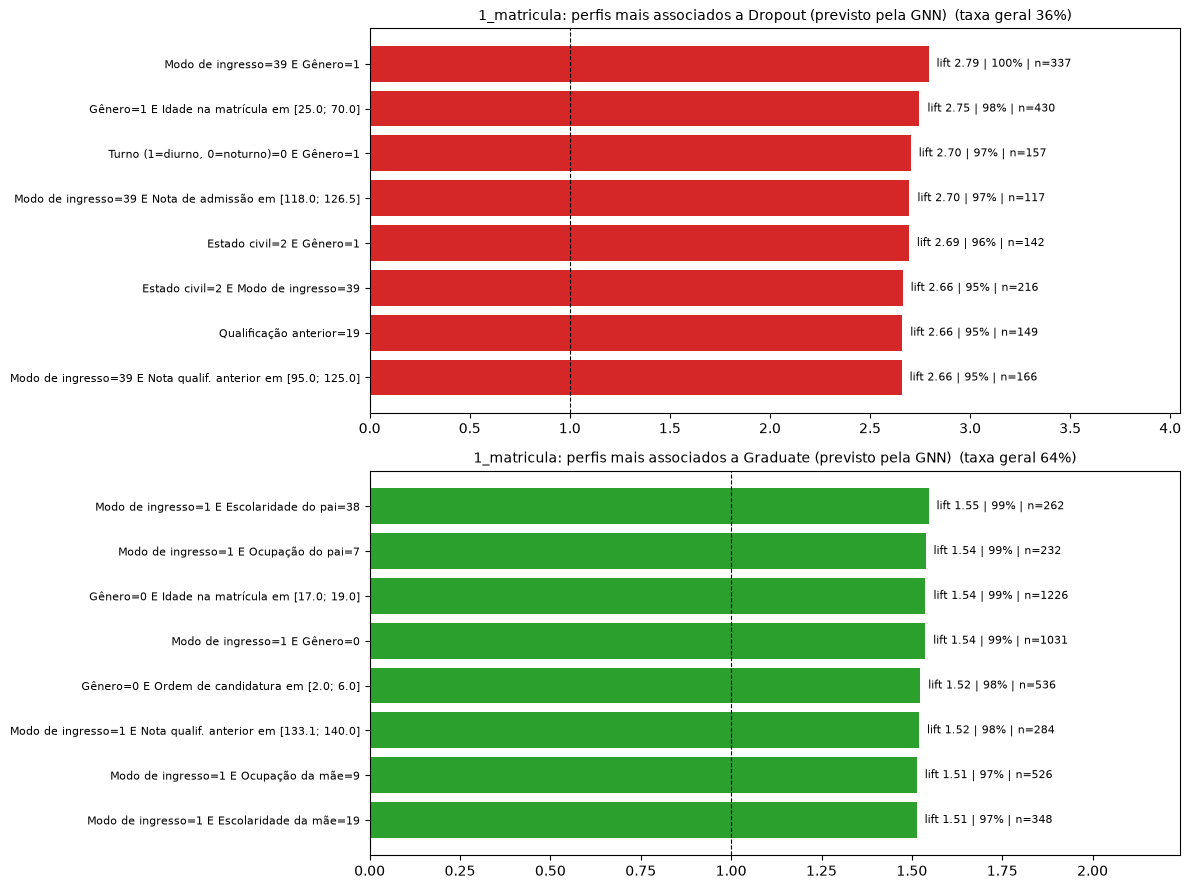

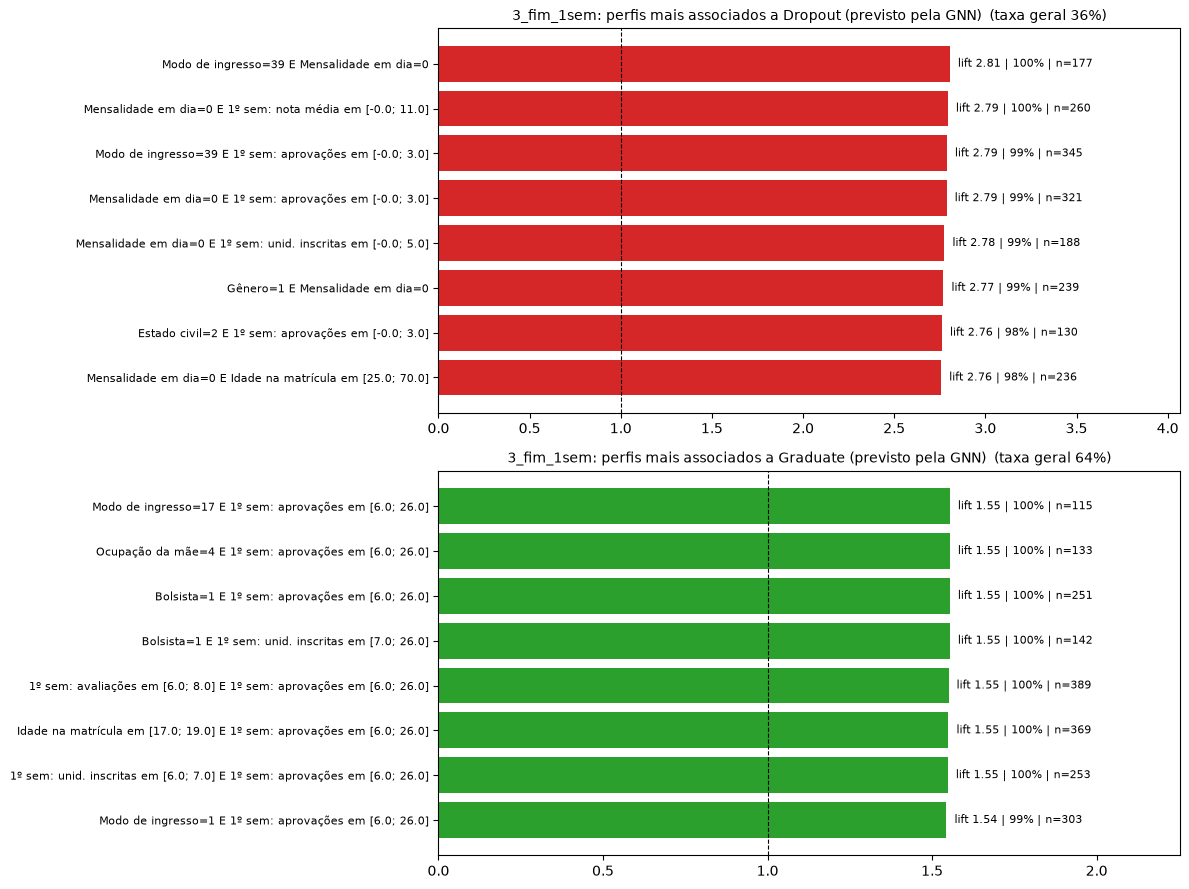

In [11]:
for jan in ["1_matricula", "3_fim_1sem"]:
    cats, nums = JANELAS[jan]; pr = OOF[jan].argmax(1); fig, ax = plt.subplots(2, 1, figsize=(12, 9)); saida = []
    for a, (cl, cor, nome) in zip(ax, [(0, "#d62728", "Dropout"), (GRAD, "#2ca02c", "Graduate")]):
        r, base = regras_lift(pr, cats, nums, cl); plota_regras(a, r, f"{jan}: perfis mais associados a {nome} (previsto pela GNN)", cor, base); r.insert(0, "desfecho_previsto", nome); saida.append(r)
    plt.tight_layout(); plt.savefig(f"figs/var2_regras_lift_{jan}.png", dpi=150); plt.show()
    pd.concat(saida).to_csv(f"resultados/var2_regras_lift_{jan}.csv", index=False)

## 6c. Alunos matriculados (Enrolled): quanto a GNN "tem certeza"?
No modo Dropout × Graduate, os matriculados ficaram fora do treino. Aqui, para cada janela:
1. **Calibração** (previsões fora da dobra dos alunos conhecidos): em cada faixa de confiança da GNN, quanto ela realmente acerta. É isso que sustenta "com X% de certeza".
2. Treinamos um modelo final com todos os alunos conhecidos (85% treino / 15% validação para a parada antecipada) e os matriculados entram como alunos novos (arestas só de entrada, vindas dos vizinhos mais parecidos do treino). A saída é a probabilidade de Dropout e de Graduate.
Atenção: matriculados são alunos que passaram do prazo, um grupo diferente do usado no treino; trate as probabilidades como estimativas, não como garantias.


=== 1_matricula: confiança da GNN x acerto real (alunos conhecidos, fora da dobra) ===


,alunos,acerto_real
faixa,,
"(0.499, 0.6]",1055,0.610
"(0.6, 0.7]",1285,0.711
"(0.7, 0.8]",985,0.757
"(0.8, 0.9]",269,0.788
"(0.9, 1.0]",36,0.861


Matriculados por previsão e confiança mínima:
          >= 60%  >= 70%  >= 80%  >= 90%
previsto                                
Dropout      182      74      11       0
Graduate     425     284      88       0

=== 3_fim_1sem: confiança da GNN x acerto real (alunos conhecidos, fora da dobra) ===


,alunos,acerto_real
faixa,,
"(0.499, 0.6]",358,0.561
"(0.6, 0.7]",372,0.699
"(0.7, 0.8]",618,0.835
"(0.8, 0.9]",1105,0.911
"(0.9, 1.0]",1177,0.968


Matriculados por previsão e confiança mínima:
          >= 60%  >= 70%  >= 80%  >= 90%
previsto                                
Dropout      195     124      68      38
Graduate     426     328     190      28


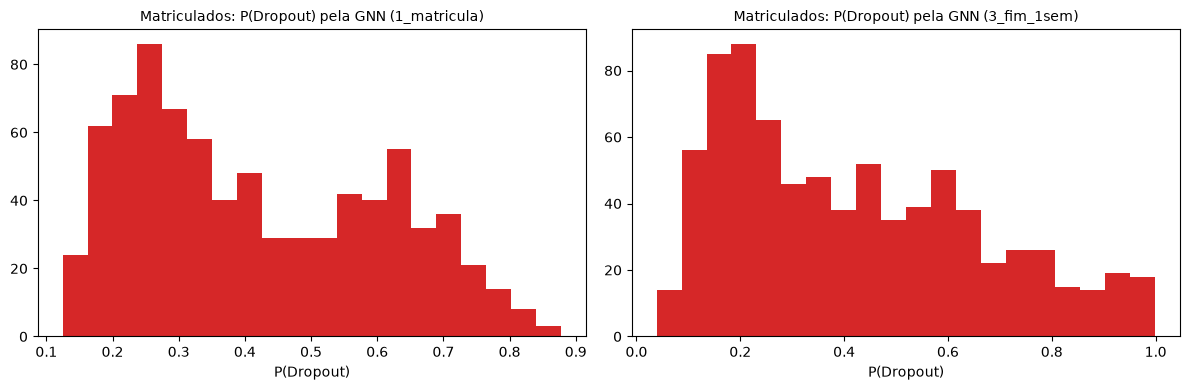

In [12]:
if not SO_DROPOUT_GRADUATE or df_enr is None:
    print("Modo de 3 classes: os 'Enrolled' já são uma classe do modelo. Esta seção só vale com SO_DROPOUT_GRADUATE = True.")
else:
    df_all = pd.concat([df, df_enr], ignore_index=True); n_lab = N; idx_enr = np.arange(n_lab, len(df_all)); fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for ax_, jan in zip(axs, ["1_matricula", "3_fim_1sem"]):
        cats, nums = JANELAS[jan]; k = K_GNN[jan]
        P_o = OOF[jan]; conf = P_o.max(1); acerto = P_o.argmax(1) == y
        cal = pd.DataFrame({"faixa": pd.cut(conf, [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], include_lowest=True), "acerto": acerto}).groupby("faixa").agg(
            alunos=("acerto", "size"), acerto_real=("acerto", "mean")).round(3)
        print(f"\n=== {jan}: confiança da GNN x acerto real (alunos conhecidos, fora da dobra) ==="); display(cal); cal.to_csv(f"resultados/var2_calibracao_{jan}.csv")
        Dall = gower(cats, nums, d=df_all, ref=np.arange(n_lab))
        tr, va = train_test_split(np.arange(n_lab), test_size=0.15, stratify=y, random_state=SEED)
        X = monta_X(cats, nums, tr, d=df_all)
        ei = arestas_indutivas(Dall, tr, np.concatenate([va, idx_enr]), k, rs=np.random.default_rng(SEED))
        torch.manual_seed(SEED); P_e = treina(SAGE(X.shape[1]), X, ei, tr, va)[idx_enr]
        out = pd.DataFrame({"aluno_matriculado": np.arange(len(idx_enr)), "p_Dropout": P_e[:, 0].round(3), "p_Graduate": P_e[:, 1].round(3)})
        out["previsto"] = np.where(P_e[:, 0] >= .5, "Dropout", "Graduate"); out["confianca"] = P_e.max(1).round(3)
        out.to_csv(f"resultados/var2_matriculados_{jan}.csv", index=False)
        print("Matriculados por previsão e confiança mínima:"); print(pd.DataFrame({f">= {l:.0%}": out[out["confianca"] >= l]["previsto"].value_counts() for l in (.6, .7, .8, .9)}).fillna(0).astype(int).to_string())
        ax_.hist(P_e[:, 0], bins=20, color="#d62728"); ax_.set_title(f"Matriculados: P(Dropout) pela GNN ({jan})", fontsize=10); ax_.set_xlabel("P(Dropout)")
    plt.tight_layout(); plt.savefig("figs/var2_matriculados.png", dpi=150); plt.show()

## 7. Como ler e escrever no artigo
* **Se GNN − MLP ≈ 0 (ou negativo) e GNN ≈ GNN embaralhada:** a vizinhança não traz sinal novo, porque as arestas foram feitas a partir dos mesmos atributos que a GNN já recebe. O objetivo do projeto **não** é ganhar de modelos de previsão (Regra do documento: se a logística ganhar, reportamos).
* **Casos ambíguos:** é o resultado útil desta variação — delimita quem a instituição precisa ouvir, porque os dados não bastam para separar evasão de sucesso.
* Lembrar: *associação não é causa*; "Enrolled" = atraso; transferência conta como evasão; perfil de risco serve para oferecer apoio, nunca para rotular.
* Referência para conferir se o seu notebook bate com o do grupo (F1 GNN − MLP): matrícula −0,020, +financeiro −0,008, 1º sem −0,007, 2º sem −0,014 (variações de ±0,01 são normais por versão do PyTorch).

Arquivos gerados: `resultados/var2_*.csv` e `figs/var2_*.png`.